# 03. MPS crime × borough income · M7

This notebook tests whether the prior-12-month MPS crime–price association varies with borough gross annual pay under **M7 only**. The three regressions use the same transaction sample, property, location and economic controls, LSOA and year-quarter fixed effects, and LSOA-clustered standard errors. Income is a borough-level proxy, not household income. Crime and income are centered, so the crime main effect is the estimated slope at mean borough income. The interaction measures how that slope changes with borough income. Both are associations; the interaction does not resolve reverse causality or measurement error.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
from linearmodels.iv import AbsorbingLS
try:
 from google.colab import drive; drive.mount('/content/drive'); ROOT=Path('/content/drive/MyDrive/HE3027 Project')
except ImportError: ROOT=Path.cwd()
DATA=ROOT/'data'; SRC=DATA/'crime_housing_merged.csv.gz'
if not SRC.is_file(): raise FileNotFoundError('Run crime_housing_project_analysis.ipynb first.')
OUT=DATA/'03_crime_mps_interaction_outputs'; OUT.mkdir(exist_ok=True)
d=pd.read_csv(SRC,low_memory=False)
d['lnprice']=np.log(d.price.where(d.price.gt(0))); d['newbuild']=d.age.eq('Y').astype(float); d['grossannualpay_k']=d.grossannualpay/1000; d['Nearest_Park_dist_km']=d['Nearest_Park_dist']/1000
for v in ['tube_distnear','bus_distnear','thamesriv_dist']: d[v+'_km']=d[v]/1000
crime_types=['mps_all','mps_violence','mps_property']; loc=['tube_distnear_km','bus_distnear_km','thamesriv_dist_km','Nearest_Park_dist_km','dist_to_cbd']; prop=['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']; econ=['hoursworked','unemployment']
for c in crime_types: d['crime_'+c]=np.log1p(d[c+'_prior12'])
valid=d.mps_exposures_available & d.mps_geography_ok & d.analysis_geography_ok
need=['lnprice','lsoacode','msoa11','oslaua','year','yearquarter','grossannualpay_k']+loc+prop+econ+['crime_'+c for c in crime_types]
s=d.loc[valid,need].dropna().copy(); s['year_fe']=s.year.astype(str); s['yearquarter_fe']=s.yearquarter.astype(str)
s['income_c']=s.grossannualpay_k-s.grossannualpay_k.mean()
for c in crime_types:
 s['crime_'+c+'_c']=s['crime_'+c]-s['crime_'+c].mean(); s['int_'+c+'_income']=s['crime_'+c+'_c']*s.income_c
specs=[('M7',['lsoacode','yearquarter_fe'],prop+loc+econ)]
rows=[]; coefs=[]
for c in crime_types:
 for model,fe,controls in specs:
  terms=['crime_'+c+'_c','income_c','int_'+c+'_income']; names=terms+controls; X=s[names].astype(float); scale=X.std().replace(0,1).to_numpy(); Xs=X/scale
  absorb=pd.DataFrame({k:pd.Categorical(s[k]) for k in fe},index=s.index) if fe else None
  fit=AbsorbingLS(s.lnprice,Xs,absorb=absorb,drop_absorbed=True).fit(cov_type='clustered',clusters=s.lsoacode,debiased=True)
  G=s.lsoacode.nunique(); crit=stats.t.ppf(.975,G-1); names_kept=list(fit.params.index)
  for v in names_kept:
   j=names.index(v); b=fit.params[v]/scale[j]; se=fit.std_errors[v]/scale[j]; coefs.append(dict(model=model,crime=c,variable=v,beta=b,se=se,ci_low=b-crit*se,ci_high=b+crit*se,p=2*stats.t.sf(abs(b/se),G-1),N=len(s),clusters=G))
  v='int_'+c+'_income'
  if v not in names_kept: raise ValueError(f'Interaction {v} is absorbed in {model}.')
  j=names.index(v); b=fit.params[v]/scale[j]; se=fit.std_errors[v]/scale[j]
  rows.append(dict(model=model,crime=c,data_source='MPS',exposure='prior12',method='Crime × borough income',N=len(s),clusters=G,beta=b,se=se,interaction_beta=b,interaction_se=se,ci_low=b-crit*se,ci_high=b+crit*se,p=2*stats.t.sf(abs(b/se),G-1),r2=fit.rsquared,fixed_effects=';'.join(fe) or 'none',absorbed_or_collinear='; '.join(v for v in names if v not in names_kept)))
results=pd.DataFrame(rows); coefficients=pd.DataFrame(coefs)
OUT.mkdir(parents=True,exist_ok=True)
results.to_csv(OUT/'interaction_regressions.csv',index=False); coefficients.to_csv(OUT/'interaction_all_coefficients.csv',index=False)
display(results); display(coefficients)


,model,crime,data_source,exposure,method,N,clusters,beta,se,interaction_beta,interaction_se,ci_low,ci_high,p,r2,fixed_effects,absorbed_or_collinear
0,M7,mps_all,MPS,prior12,Crime × borough income,338347,4647,-0.000240,0.001397,-0.000240,0.001397,-0.00298,0.002499,0.863396,0.756130,lsoacode;yearquarter_fe,
1,M7,mps_violence,MPS,prior12,Crime × borough income,338347,4647,0.000546,0.000773,0.000546,0.000773,-0.00097,0.002061,0.480337,0.756131,lsoacode;yearquarter_fe,
2,M7,mps_property,MPS,prior12,Crime × borough income,338347,4647,-0.000989,0.001209,-0.000989,0.001209,-0.00336,0.001382,0.413447,0.756131,lsoacode;yearquarter_fe,


,model,crime,variable,beta,se,ci_low,ci_high,p,N,clusters
0,M7,mps_all,crime_mps_all_c,-0.000693,0.006348,-0.013137,0.011752,9.131250e-01,338347,4647
1,M7,mps_all,income_c,-0.008178,0.000934,-0.010009,-0.006347,2.797304e-18,338347,4647
2,M7,mps_all,int_mps_all_income,-0.000240,0.001397,-0.002980,0.002499,8.633964e-01,338347,4647
3,M7,mps_all,detached_dum,0.629664,0.014396,0.601441,0.657887,0.000000e+00,338347,4647
4,M7,mps_all,semi_d_dum,0.356990,0.012954,0.331593,0.382386,5.692125e-155,338347,4647
5,M7,mps_all,terrace_dum,0.224248,0.012761,0.199230,0.249265,5.600694e-67,338347,4647
6,M7,mps_all,freehold,0.389868,0.012474,0.365413,0.414323,8.454511e-195,338347,4647
7,M7,mps_all,newbuild,0.181451,0.009516,0.162796,0.200106,4.127013e-78,338347,4647
8,M7,mps_all,tube_distnear_km,0.009028,0.013177,-0.016805,0.034862,4.932845e-01,338347,4647
9,M7,mps_all,bus_distnear_km,0.262756,0.019564,0.224401,0.301111,2.247716e-40,338347,4647


For each crime type, the marginal crime slope is β_crime + β_interaction × (borough pay − mean borough pay), where pay is measured in GBP 1,000. A crime main effect near zero at mean pay does not constrain the interaction to zero. The interaction coefficient tests whether the slope changes with pay. Both terms may still face endogeneity and limited within-LSOA variation. Standard errors are clustered by LSOA.

## M7 figures and descriptive checks

The plots show the common sample, the three M7 interaction estimates, and implied crime slopes across observed borough-pay values. Slope bands use the full clustered covariance between the crime main effect and interaction.

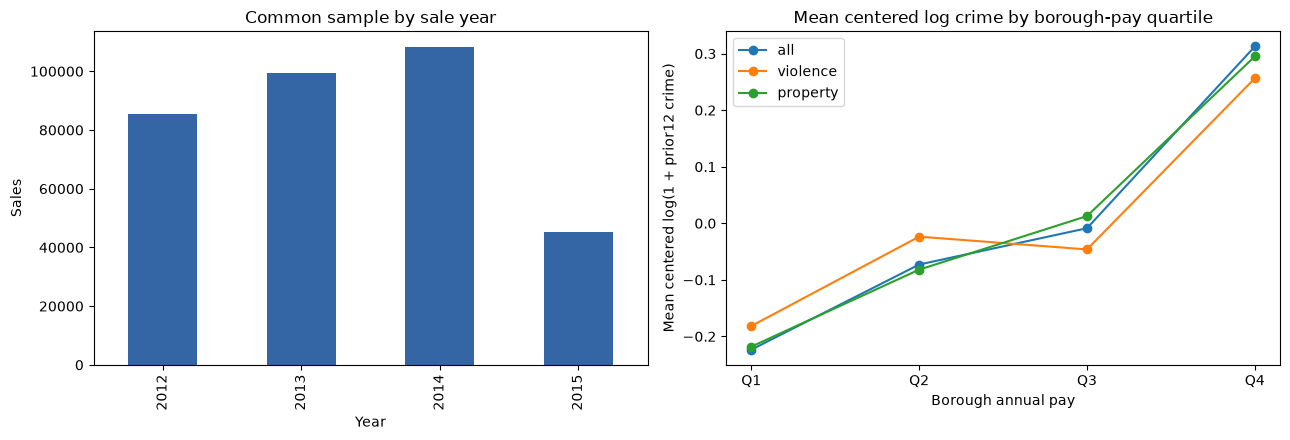

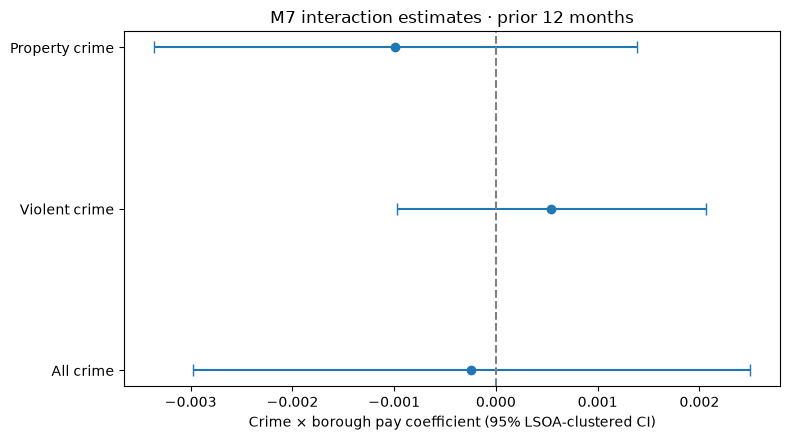

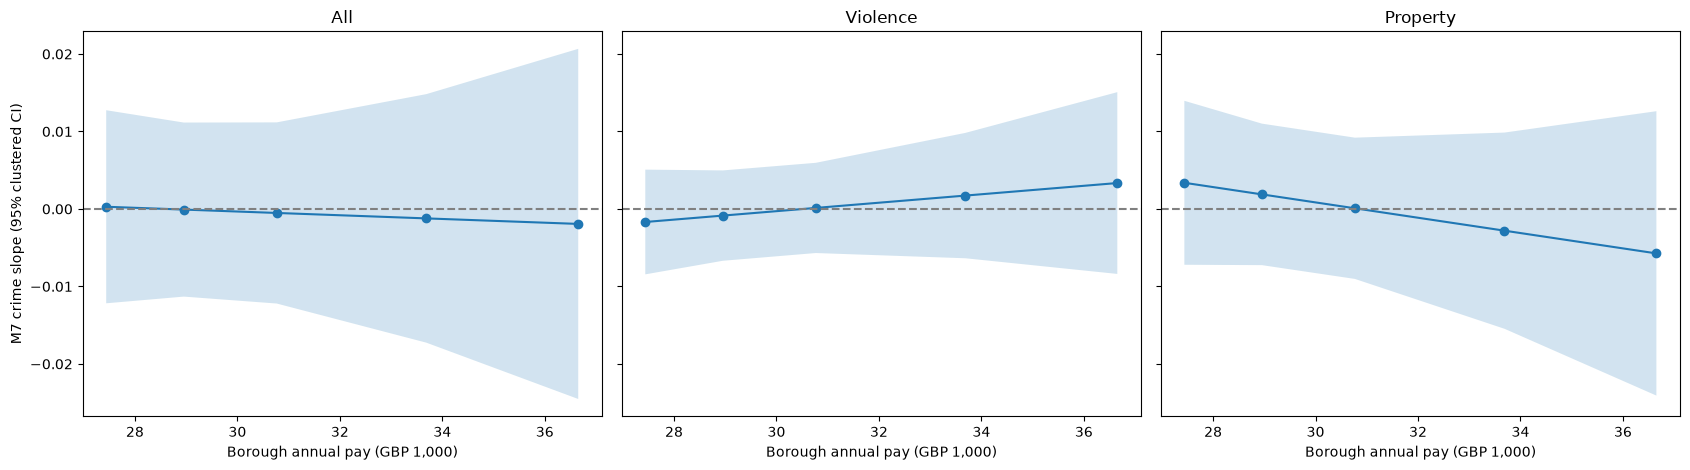

In [2]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
s.groupby('year').size().plot.bar(ax=axes[0],color='#3465a4')
axes[0].set_title('Common sample by sale year');axes[0].set_ylabel('Sales');axes[0].set_xlabel('Year')
for c in crime_types:
    b=s[['grossannualpay_k','crime_'+c+'_c']].copy()
    b['pay_group']=pd.qcut(b.grossannualpay_k,4,duplicates='drop')
    means=b.groupby('pay_group',observed=True)['crime_'+c+'_c'].mean()
    axes[1].plot(range(len(means)),means.to_numpy(),marker='o',label=c.replace('mps_',''))
axes[1].set_xticks(range(len(means)),[f'Q{i+1}' for i in range(len(means))])
axes[1].set_title('Mean centered log crime by borough-pay quartile')
axes[1].set_xlabel('Borough annual pay');axes[1].set_ylabel('Mean centered log(1 + prior12 crime)');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'sample_and_income_patterns.png',dpi=170,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(8,4.5))
b=results.set_index('crime').loc[crime_types]
y=np.arange(len(b))
ax.errorbar(b.beta,y,xerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=4)
ax.axvline(0,color='grey',linestyle='--')
ax.set_yticks(y,['All crime','Violent crime','Property crime'])
ax.set_xlabel('Crime × borough pay coefficient (95% LSOA-clustered CI)')
ax.set_title('M7 interaction estimates · prior 12 months')
fig.tight_layout();fig.savefig(OUT/'m7_interaction_estimates.png',dpi=170,bbox_inches='tight');plt.show()

pay_grid=np.quantile(s.income_c,[.1,.25,.5,.75,.9])
fig,axes=plt.subplots(1,3,figsize=(17,4.8),sharey=True)
for ax,c in zip(axes,crime_types):
    names=['crime_'+c+'_c','int_'+c+'_income']
    X=s[names+['income_c']+prop+loc+econ].astype(float)
    scale=X.std().replace(0,1).to_numpy();Xs=X/scale
    absorbed=pd.DataFrame({k:pd.Categorical(s[k]) for k in ['lsoacode','yearquarter_fe']},index=s.index)
    fit=AbsorbingLS(s.lnprice,Xs,absorb=absorbed,drop_absorbed=True).fit(cov_type='clustered',clusters=s.lsoacode,debiased=True)
    b=fit.params.loc[names].to_numpy()/scale[:2]
    V=fit.cov.loc[names,names].to_numpy()/np.outer(scale[:2],scale[:2])
    design=np.column_stack([np.ones(len(pay_grid)),pay_grid])
    slope=design@b;se=np.sqrt(np.einsum('ij,jk,ik->i',design,V,design))
    crit=stats.t.ppf(.975,s.lsoacode.nunique()-1)
    ax.plot(pay_grid+s.grossannualpay_k.mean(),slope,marker='o')
    ax.fill_between(pay_grid+s.grossannualpay_k.mean(),slope-crit*se,slope+crit*se,alpha=.2)
    ax.axhline(0,color='grey',linestyle='--');ax.set_title(c.replace('mps_','').title())
    ax.set_xlabel('Borough annual pay (GBP 1,000)')
axes[0].set_ylabel('M7 crime slope (95% clustered CI)')
fig.tight_layout();fig.savefig(OUT/'m7_crime_slopes_by_income.png',dpi=170,bbox_inches='tight');plt.show()
